# Predicting Creadit Card Fraud (EDA)

In [5]:
import matplotlib.pyplot as plt
from pathlib import Path
import seaborn as sns
import pandas as pd

In [6]:
_CURRENT_PATH = Path.cwd().parent
_DATA_PATH = _CURRENT_PATH / "data"
_RAW_DATASET_PATH = _DATA_PATH / "raw"
_TRAIN_DATASET_PATH = _RAW_DATASET_PATH / "train.csv"

## Read Train Dataset

In [7]:
df = pd.read_csv(_TRAIN_DATASET_PATH)
df_copy = df.copy()

In [8]:
df_copy.info()

<class 'pandas.DataFrame'>
RangeIndex: 699960 entries, 0 to 699959
Data columns (total 26 columns):
 #   Column                        Non-Null Count   Dtype  
---  ------                        --------------   -----  
 0   id                            699960 non-null  int64  
 1   amount_usd                    699960 non-null  float64
 2   hours_since_last_txn          699960 non-null  float64
 3   txn_count_last_24h            699960 non-null  int64  
 4   distance_from_home_km         699960 non-null  float64
 5   card_age_months               699960 non-null  int64  
 6   customer_age                  699960 non-null  int64  
 7   account_balance_usd           699960 non-null  float64
 8   cvv_retry_count               699960 non-null  int64  
 9   velocity_score                699960 non-null  float64
 10  time_of_day_hour              699960 non-null  int64  
 11  day_of_week                   699960 non-null  int64  
 12  merchant_risk_score           699960 non-null  float64


## Seperate Columns With Data Types

In [9]:
numerical_columns = df_copy.select_dtypes(include="number").columns.tolist()
string_columns    = df_copy.select_dtypes(include="string").columns.tolist()

## Describe Columns

In [10]:
df_copy[numerical_columns].describe()

,id,amount_usd,hours_since_last_txn,txn_count_last_24h,distance_from_home_km,card_age_months,customer_age,account_balance_usd,cvv_retry_count,velocity_score,time_of_day_hour,day_of_week,merchant_risk_score,prior_disputes,is_fraud
count,699960.000000,699960.000000,699960.000000,699960.000000,699960.000000,699960.000000,699960.000000,699960.000000,699960.000000,699960.000000,699960.000000,699960.000000,699960.000000,699960.000000,699960.000000
mean,349979.500000,79.893068,6.633734,2.984092,13.587575,46.862982,51.430286,2064.998070,0.085472,18.929445,11.761915,2.981733,35.217648,0.152769,0.016700
std,202061.191549,205.173538,6.290133,1.498998,11.617325,5.579190,17.899150,3400.132922,0.289524,10.864385,6.869164,2.001652,12.628361,0.381126,0.128143
min,0.000000,1.000000,0.010000,0.000000,0.000000,25.000000,18.000000,58.250000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,174989.750000,15.810000,2.110000,2.000000,4.430000,43.000000,38.000000,834.120000,0.000000,11.400000,6.000000,1.000000,26.400000,0.000000,0.000000
50%,349979.500000,27.250000,4.730000,3.000000,10.220000,47.000000,52.000000,1382.740000,0.000000,18.600000,12.000000,3.000000,34.200000,0.000000,0.000000
75%,524969.250000,43.110000,9.190000,4.000000,19.750000,51.000000,66.000000,2517.020000,0.000000,26.000000,18.000000,5.000000,42.700000,0.000000,0.000000
max,699959.000000,6872.690000,51.980000,11.000000,57.930000,73.000000,81.000000,99701.390000,3.000000,72.900000,23.000000,6.000000,100.000000,4.000000,1.000000


In [11]:
missing_mask = df_copy.isna()
missing_report = pd.DataFrame({
    "missing_count": missing_mask.sum(),
    "missing_pct": missing_mask.mean() * 100
})
missing_report

,missing_count,missing_pct
id,0,0.0
amount_usd,0,0.0
hours_since_last_txn,0,0.0
txn_count_last_24h,0,0.0
distance_from_home_km,0,0.0
card_age_months,0,0.0
customer_age,0,0.0
account_balance_usd,0,0.0
cvv_retry_count,0,0.0
velocity_score,0,0.0


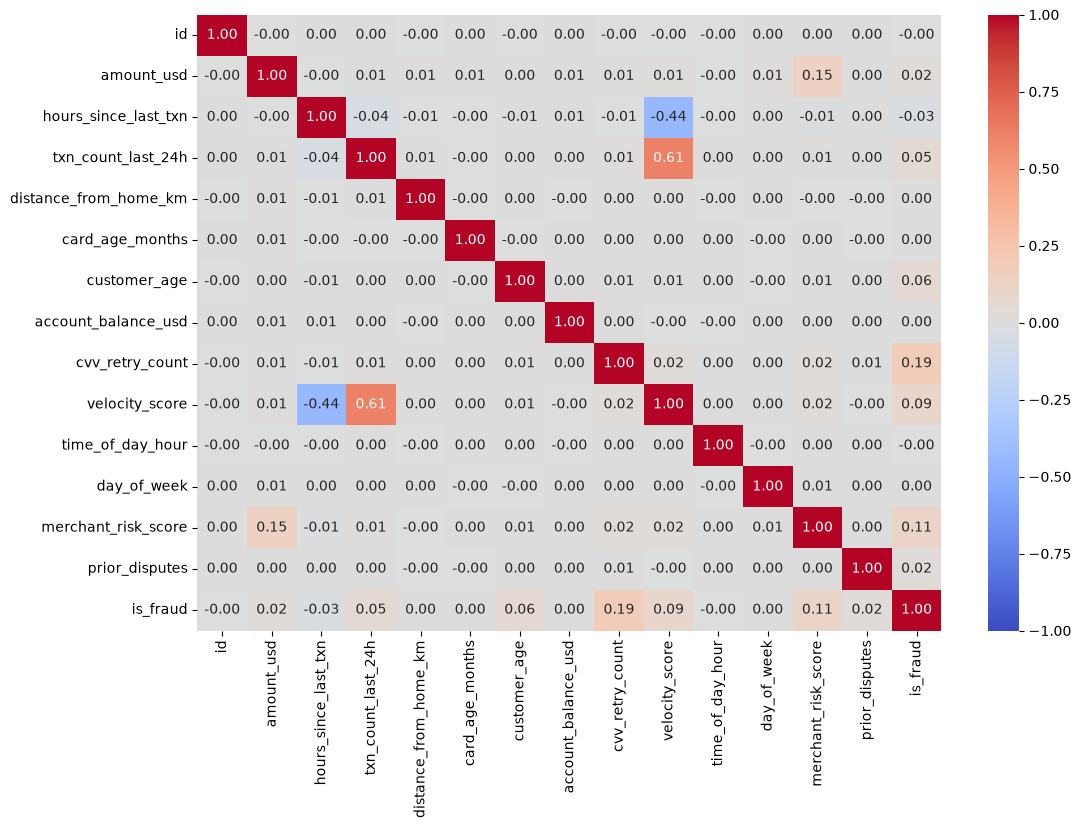

In [ ]:
corr = df_copy[numerical_columns].corr(method="spearman", numeric_only=True)
plt.figure(figsize=(12, 8))
sns.heatmap(
    corr,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)
plt.show()

In [ ]:
df_copy["merchant_category"].unique().tolist()

"card_type", "merchant_category", "auth_method", "channel", "device_type"

('card_type', 'merchant_category')